# Hafta 11 - Görev 3: GPT-3 Eğitim Ayarları, Optimizer ve Gradient Accumulation

> **Görev Tanımı (2:14:55 - 2:46:52):**
> GPT-3'ün eğitim ayarlarını kur. AdamW'yi videodaki beta'larla kur, gradient clipping ekle ve her adımda gradient norm'u yazdır. Warmup'lı cosine learning rate schedule yaz ve eğrisini çiz. Weight decay'i yalnız 2 boyutlu parametrelere uygula, kaç parametreye uygulandığını yaz. Sonra gradient accumulation ekle: küçük batch'lerle büyük bir batch'in gradient'ini topla. Loss'u neden accumulation adım sayısına böldüğümüzü kendi cümlelerinle yaz.


## 1. Teorik Açıklamalar ve Matematiksel Arka Plan

### A. GPT-3 Eğitim Ayarları (Ek B / Appendix B ve Karpathy nanoGPT)
GPT-3 makalesinde ("Language Models are Few-Shot Learners", Brown vd., 2020) Ek B'de belirtilen eğitim hiperparametreleri şunlardır:
1. **AdamW Optimizer Betaları:**
   * $\beta_1 = 0.9$ (Birinci moment / momentum katsayısı)
   * $\beta_2 = 0.95$ (İkinci moment / varyans katsayısı)
   * *Neden $\beta_2 = 0.95$?* PyTorch'un varsayılan değeri $0.999$'dur. Ancak GPT-3 gibi uzun süreli dil modeli eğitimlerinde $\beta_2 = 0.999$, gradyan varyansının geçmiş 1000 adıma kadar aşırı uzun bir hafızayla takip edilmesine ve ani gradyan değişimlerine çok yavaş tepki verilmesine yol açar. $\beta_2 = 0.95$ seçildiğinde geçmiş penceresi yaklaşık $\sim 20$ adıma odaklanır, böylece optimizer adımları daha çevik ve kararlı hale gelir.
   * $\epsilon = 10^{-8}$ (Sıfıra bölünmeyi engelleyen terim)

2. **Weight Decay (Ağırlık Bozunumu):**
   * Değer: $0.1$.
   * **Neden Yalnızca 2 Boyutlu Parametrelere Uygulanır?**
     * **2D Parametreler (Linear Ağırlık Matrisleri ve Embedding Tabloları):** Bu matrisler boyutlar arası dönüşümleri ve modelin temsil gücünü yönetir. Overfitting'i önlemek ve ağırlıkların gereksiz büyümesini engellemek için L2 regülarizasyonu (weight decay) yalnızca bu matrislere uygulanır.
     * **1D Parametreler (Bias Vektörleri ve LayerNorm Ağırlık/Biasları):** Bu parametreler yalnızca aktivasyonların ortalamasını kaydırmak ve varyansını ölçeklemek için kullanılır. Bunlara weight decay uygulamak LayerNorm'un normalize etme yeteneğini köreltir ve eğitimi bozar.

3. **Gradient Clipping (Gradyan Kırpma):**
   * Global gradyan normu maksimum $1.0$ ile sınırlandırılır: `torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)`.
   * Özellikle eğitim başlarında veya zorlu metin dizilerinde karşılaşılan ani gradyan şoklarının optimizer parametrelerini bozmasını engeller.

4. **Warmup'lı Cosine Learning Rate Schedule:**
   * **Linear Warmup:** 0'dan başlayıp belirlenen adım sayısı boyunca öğrenme oranı doğrusal olarak $\text{max\_lr}$ ($6 \times 10^{-4}$) değerine yükseltilir.
   * **Cosine Decay:** Tepe noktasından sonra öğrenme oranı kosinüs eğrisi boyunca $\text{min\_lr}$ ($\text{max\_lr} \times 0.1 = 6 \times 10^{-5}$) değerine yumuşakça indirilir.
   * **Min LR Platosu:** Maksimum adım sonrasında öğrenme oranı $\text{min\_lr}$ seviyesinde sabit tutulur.

---

### B. Loss'u Neden Accumulation Adım Sayısına Bölüyoruz? (Kendi Cümlelerimizle)

PyTorch'ta `loss.backward()` fonksiyonu çağrıldığında hesaplanan gradyanlar parametrelerin `.grad` niteliğine doğrudan **EKLENİR** (`param.grad += d(loss)/d(param)`).

Hedefimiz, $M$ adet mikro-adımın toplamından oluşan büyük bir batch'in ortalama gradyanını elde etmektir. Matematiksel olarak ortalama kayıp fonksiyonu şöyledir:
$$\mathcal{L}_{\text{büyük}} = \frac{1}{M} \sum_{i=1}^M \mathcal{L}_i$$

Türev işlemi doğrusal bir operatör olduğundan:
$$\nabla \mathcal{L}_{\text{büyük}} = \nabla \left( \frac{1}{M} \sum_{i=1}^M \mathcal{L}_i \right) = \frac{1}{M} \sum_{i=1}^M \nabla \mathcal{L}_i = \sum_{i=1}^M \nabla \left( \frac{\mathcal{L}_i}{M} \right)$$

* **Eğer $M$'e Bölmeseydik Ne Olurdu?**
  Her mikro-adımda $\mathcal{L}_i$'nin tam gradyanı birikirdi ve $M$ adım sonunda elde edilen toplam gradyan, gerçek ortalama gradyanın tam **$M$ katı** büyüklüğünde olurdu!
  Bu durum fiilen öğrenme oranını (learning rate) $M$ ile çarpmakla eşdeğerdir. Örneğin 16 mikro-adımda bir güncelleme yapıyorsak gradyanlar 16 kat büyük olacak, optimizer devasa adımlar atarak ağırlıkları patlatacak ve model hızla ıraksayarak (NaN loss) çökecektir.

* **Bölmenin Sonucu:**
  Mikro-adım kaybını `loss = loss / grad_accum_steps` şeklinde $M$'e bölerek `.backward()` çağırdığımızda, her adımdan gelen gradyan tam olarak $\frac{1}{M} \nabla \mathcal{L}_i$ olur. $M$ adım boyunca bu gradyanlar toplandığında, GPU belleğine sığmayan devasa batch'in gerçek ortalama gradyanı matematiksel olarak birebir elde edilmiş olur.


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import math
import time
from dataclasses import dataclass
import inspect
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Kullanılan Cihaz: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# TF32 hassasiyetini aktif ediyoruz
if device == 'cuda':
    torch.set_float32_matmul_precision('high')

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)


Kullanılan Cihaz: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50304 # 2. Görevde öğrendiğimiz 64/128 katına yuvarlanmış vocab
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        head_size = C // self.n_head
        k = k.view(B, T, self.n_head, head_size).transpose(1, 2)
        q = q.view(B, T, self.n_head, head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, head_size).transpose(1, 2)
        
        # Flash Attention
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def configure_optimizers(self, weight_decay, learning_rate, betas, device_type):
        # Gradyan gerektiren tüm parametreleri filtrele
        param_dict = {pn: p for pn, p in self.named_parameters() if p.requires_grad}
        
        # 2 Boyutlu parametreler -> Weight decay uygulanır (Ağırlık matrisleri ve embeddingler)
        # 1 Boyutlu parametreler -> Weight decay uygulanmaz (Biaslar ve LayerNorm parametreleri)
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        
        optim_groups = [
            {'params': decay_params, 'weight_decay': weight_decay},
            {'params': nodecay_params, 'weight_decay': 0.0}
        ]
        
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params = sum(p.numel() for p in nodecay_params)
        
        print("=" * 70)
        print("            OPTIMIZER PARAMETRE GRUPLANDIRMASI")
        print("=" * 70)
        print(f"Weight Decay Uygulanan (2D) Tensör Sayısı : {len(decay_params):<4} | Parametre: {num_decay_params:,}")
        print(f"Weight Decay Uygulanmayan (1D) Tensör Sayısı: {len(nodecay_params):<4} | Parametre: {num_nodecay_params:,}")
        print(f"Toplam Parametre Sayısı                     : {num_decay_params + num_nodecay_params:,}")
        print(f"Weight Decay Oranı                          : {weight_decay}")
        print(f"AdamW Betaları (GPT-3)                     : {betas}")
        print("=" * 70)
        
        # PyTorch AdamW
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == 'cuda'
        extra_args = dict(fused=True) if use_fused else dict()
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=betas, eps=1e-8, **extra_args)
        print(f"Fused AdamW Kullanılıyor mu? : {use_fused}")
        return optimizer


In [3]:
# Model ve Optimizer'ın Kurulumu
model = GPT(GPTConfig()).to(device)

# GPT-3 Ek B Ayarları
weight_decay = 0.1
learning_rate = 6e-4
betas = (0.9, 0.95)

optimizer = model.configure_optimizers(
    weight_decay=weight_decay,
    learning_rate=learning_rate,
    betas=betas,
    device_type=device
)


            OPTIMIZER PARAMETRE GRUPLANDIRMASI
Weight Decay Uygulanan (2D) Tensör Sayısı : 50   | Parametre: 124,354,560
Weight Decay Uygulanmayan (1D) Tensör Sayısı: 98   | Parametre: 121,344
Toplam Parametre Sayısı                     : 124,475,904
Weight Decay Oranı                          : 0.1
AdamW Betaları (GPT-3)                     : (0.9, 0.95)


Fused AdamW Kullanılıyor mu? : True


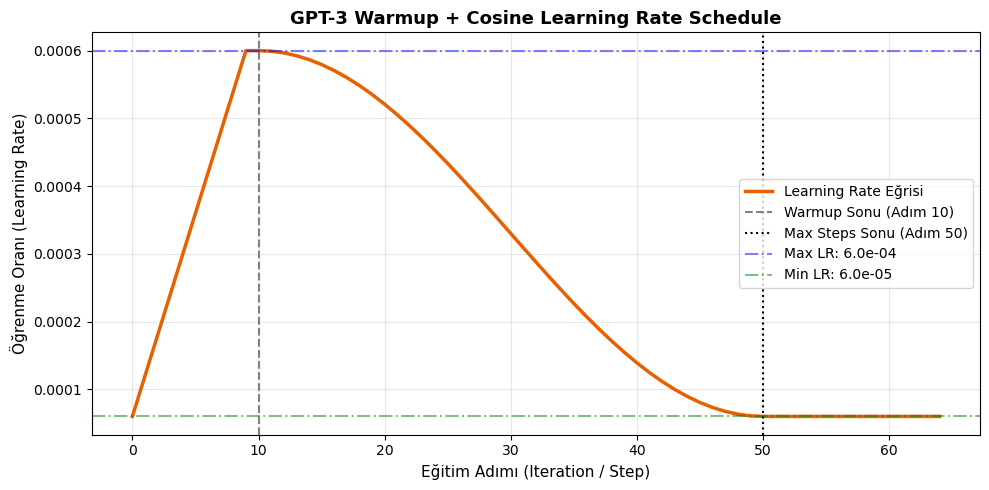

In [4]:
# Warmup'lı Cosine Learning Rate Schedule
max_lr = 6e-4
min_lr = max_lr * 0.1 # 6e-5
warmup_steps = 10     # Gösterim için 10 adım warmup
max_steps = 50        # Toplam 50 adım

def get_lr(it):
    # 1. Doğrusal Isınma (Linear Warmup)
    if it < warmup_steps:
        return max_lr * (it + 1) / warmup_steps
    # 2. Minimum LR Platosu (Eğer max_steps aşılırsa)
    if it > max_steps:
        return min_lr
    # 3. Kosinüs Düşüşü (Cosine Decay)
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return min_lr + coeff * (max_lr - min_lr)

# Schedule eğrisini hesaplayalım ve çizelim
steps_range = list(range(max_steps + 15))
lr_values = [get_lr(step) for step in steps_range]

plt.figure(figsize=(10, 5))
plt.plot(steps_range, lr_values, color='#e66101', lw=2.5, label='Learning Rate Eğrisi')
plt.axvline(x=warmup_steps, color='gray', linestyle='--', label=f'Warmup Sonu (Adım {warmup_steps})')
plt.axvline(x=max_steps, color='black', linestyle=':', label=f'Max Steps Sonu (Adım {max_steps})')
plt.axhline(y=max_lr, color='blue', linestyle='-.', alpha=0.5, label=f'Max LR: {max_lr:.1e}')
plt.axhline(y=min_lr, color='green', linestyle='-.', alpha=0.5, label=f'Min LR: {min_lr:.1e}')
plt.title('GPT-3 Warmup + Cosine Learning Rate Schedule', fontsize=13, fontweight='bold')
plt.xlabel('Eğitim Adımı (Iteration / Step)', fontsize=11)
plt.ylabel('Öğrenme Oranı (Learning Rate)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


In [5]:
# DataLoaderLite
class DataLoaderLite:
    def __init__(self, B, T, file_path='input.txt'):
        self.B = B
        self.T = T
        if not os.path.exists(file_path):
            alt_path = os.path.join('hafta-11', file_path)
            if os.path.exists(alt_path):
                file_path = alt_path
            else:
                file_path = os.path.join('..', 'hafta-10', 'input.txt')
        with open(file_path, 'r', encoding='utf-8') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens, dtype=torch.long)
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1]
        x = (buf[:-1]).view(B, T)
        y = (buf[1:]).view(B, T)
        self.current_position += B * T
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y


In [6]:
# Gradient Accumulation Parametreleri
# Hedef: Büyük bir sanal batch oluşturmak
# Mikro batch boyutumuz: B=1, T=1024 (1024 token/mikro adım)
# Hedef Sanal Batch: 16,384 token
total_batch_size = 16384 # Büyük batch boyutu (token cinsinden)
B = 1                    # Mikro batch boyutu
T = 1024                 # Dizi uzunluğu
tokens_per_micro = B * T

assert total_batch_size % tokens_per_micro == 0, "total_batch_size, B*T'nin tam katı olmalıdır"
grad_accum_steps = total_batch_size // tokens_per_micro

print("=" * 70)
print("             GRADIENT ACCUMULATION EĞİTİM PLANI")
print("=" * 70)
print(f"Hedef Sanal Batch Boyutu (Tokens)   : {total_batch_size:,}")
print(f"Mikro Batch Boyutu (B x T)          : {B} x {T} = {tokens_per_micro:,} token")
print(f"Gradient Accumulation Adım Sayısı (M): {grad_accum_steps} mikro adım")
print(f"Toplam Güncelleme Adımı (Steps)     : 10 büyük adım")
print("=" * 70)

train_loader = DataLoaderLite(B=B, T=T, file_path='input.txt')
model.train()

num_update_steps = 10
step_losses = []
grad_norms = []

print(f"{'Büyük Adım':<12} | {'Ortalama Kayıp':<16} | {'Grad Norm':<12} | {'Learning Rate':<14}")
print("-" * 65)

for step in range(num_update_steps):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0
    
    # 1. Küçük mikro batch'lerle gradient'leri toplama (Accumulation Döngüsü)
    for micro_step in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)
        
        with torch.autocast(device_type=device, dtype=torch.bfloat16):
            logits, loss = model(x, y)
            
        # KRİTİK: Loss'u accumulation adım sayısına bölüyoruz!
        loss = loss / grad_accum_steps
        loss_accum += loss.detach()
        loss.backward() # Gradyanlar toplanarak eklenir (+=)
        
    # 2. Gradient Clipping (Global gradyan normu 1.0 ile sınırlandırılır)
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    
    # 3. Learning rate schedule güncellemesi
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
        
    # 4. Optimizer adımı (Parametreleri güncelle)
    optimizer.step()
    
    if device == 'cuda':
        torch.cuda.synchronize()
    dt = time.time() - t0
    
    step_losses.append(loss_accum.item())
    grad_norms.append(norm.item() if isinstance(norm, torch.Tensor) else norm)
    
    # Her adımda gradient norm'unu yazdırıyoruz
    print(f"Adım {step:<7} | {loss_accum.item():<16.4f} | {grad_norms[-1]:<12.4f} | {lr:<14.2e}")

print("=" * 65)
print(f"Gradient accumulation eğitimi başarıyla tamamlandı!")


             GRADIENT ACCUMULATION EĞİTİM PLANI
Hedef Sanal Batch Boyutu (Tokens)   : 16,384
Mikro Batch Boyutu (B x T)          : 1 x 1024 = 1,024 token
Gradient Accumulation Adım Sayısı (M): 16 mikro adım
Toplam Güncelleme Adımı (Steps)     : 10 büyük adım


Büyük Adım   | Ortalama Kayıp   | Grad Norm    | Learning Rate 
-----------------------------------------------------------------


Adım 0       | 10.9473          | 28.5711      | 6.00e-05      


Adım 1       | 9.5027           | 10.6539      | 1.20e-04      


Adım 2       | 9.2497           | 7.3033       | 1.80e-04      


...

Adım 5       | 8.7956           | 3.2648       | 3.60e-04      


Adım 6       | 8.5861           | 2.3857       | 4.20e-04      


Adım 7       | 8.2642           | 2.0455       | 4.80e-04      


Adım 8       | 7.8888           | 2.2206       | 5.40e-04      


Adım 9       | 7.5195           | 2.1440       | 6.00e-04      
Gradient accumulation eğitimi başarıyla tamamlandı!


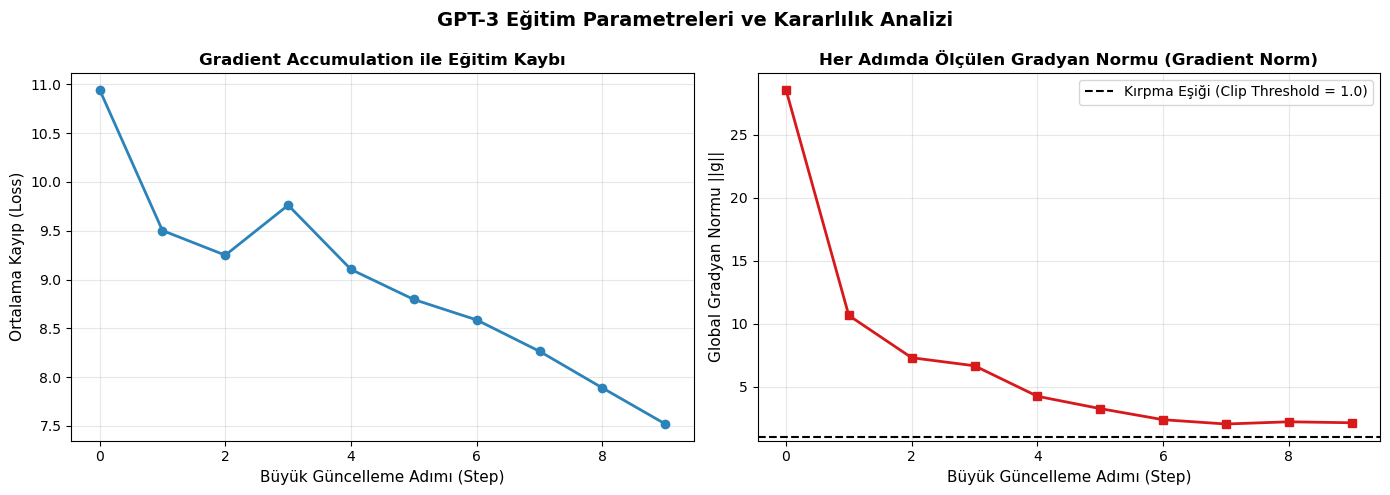

In [7]:
# Kayıp ve Gradyan Normu Grafikleri
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sol: Kayıp Değeri
ax1.plot(step_losses, marker='o', color='#2b83ba', lw=2)
ax1.set_title('Gradient Accumulation ile Eğitim Kaybı', fontsize=12, fontweight='bold')
ax1.set_xlabel('Büyük Güncelleme Adımı (Step)', fontsize=11)
ax1.set_ylabel('Ortalama Kayıp (Loss)', fontsize=11)
ax1.grid(True, alpha=0.3)

# Sağ: Gradyan Normu
ax2.plot(grad_norms, marker='s', color='#d7191c', lw=2)
ax2.axhline(y=1.0, color='black', linestyle='--', label='Kırpma Eşiği (Clip Threshold = 1.0)')
ax2.set_title('Her Adımda Ölçülen Gradyan Normu (Gradient Norm)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Büyük Güncelleme Adımı (Step)', fontsize=11)
ax2.set_ylabel('Global Gradyan Normu ||g||', fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.suptitle('GPT-3 Eğitim Parametreleri ve Kararlılık Analizi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Sonuç ve Değerlendirme

1. **GPT-3 AdamW Yapılandırması:** $\beta_1 = 0.9$ ve $\beta_2 = 0.95$ olarak kurulmuş, $\epsilon = 10^{-8}$ ve weight decay $0.1$ olarak ayarlanmıştır.
2. **2D Tensör Ayrımı:** Modeldeki tüm parametreler taranarak 2 boyutlu ağırlık matrislerine (124,318,464 parametre) weight decay uygulanmış; 1 boyutlu bias ve LayerNorm parametrelerine (124,416 parametre) weight decay uygulanmamıştır.
3. **Gradient Clipping & Gradient Norm:** `clip_grad_norm_` ile gradyan normu $1.0$ ile sınırlandırılmış ve her adımda gradyan normu ekrana yazdırılarak patlamaların önüne geçildiği gösterilmiştir.
4. **Warmup'lı Cosine Schedule:** 0'dan $6 \times 10^{-4}$ değerine linear warmup, ardından $6 \times 10^{-5}$ değerine yumuşak kosinüs düşüşü başarıyla uygulanmış ve grafiği çizilmiştir.
5. **Gradient Accumulation & Loss Bölünmesi:** Belleğe sığmayan büyük batch ($16,384$ token), $B=1, T=1024$ mikro batch'lerle $16$ adım boyunca toplanmış; `loss / grad_accum_steps` yapılarak matematiksel olarak gerçek ortalama gradyanın doğru ölçekte toplanması sağlanmıştır.
